# Exercise 10 - Deep neural network on the MNIST data

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
import keras_tuner as kt
import os
import tensorboard

In [2]:
keras.utils.set_random_seed(42)
(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.mnist.load_data()

X_train_full = X_train_full.astype("float32") / 255.
X_test = X_test.astype("float32") / 255.

X_train, y_train = X_train_full[5000:], y_train_full[5000:]
X_val, y_val = X_train_full[:5000], y_train_full[:5000]

print(X_train.shape, X_val.shape, X_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 7s 1us/step 
(55000, 28, 28) (5000, 28, 28) (10000, 28, 28)


In [3]:
def build_mlp(learning_rate=1e-3, units=300, dropout=0.0):
    model = keras.Sequential([
        keras.layers.Input(shape=(28, 28)),
        keras.layers.Flatten(),
        keras.layers.Dense(units, activation="relu"),
        keras.layers.Dense(units, activation="relu"),
        keras.layers.Dense(units // 2, activation="relu"),
        keras.layers.Dropout(dropout),
        keras.layers.Dense(10, activation="softmax")
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

model = build_mlp()
early_stop = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True)
history = model.fit(X_train, y_train, epochs=30, batch_size=128, validation_data=(X_val, y_val), callbacks=[early_stop])

Epoch 1/30
430/430 ━━━━━━━━━━━━━━━━━━━━ 18s 34ms/step - accuracy: 0.9245 - loss: 0.2568 - val_accuracy: 0.9680 - val_loss: 0.1150
Epoch 2/30
430/430 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - accuracy: 0.9708 - loss: 0.0928 - val_accuracy: 0.9716 - val_loss: 0.0887
Epoch 3/30
430/430 ━━━━━━━━━━━━━━━━━━━━ 20s 32ms/step - accuracy: 0.9814 - loss: 0.0597 - val_accuracy: 0.9740 - val_loss: 0.0874
Epoch 4/30
430/430 ━━━━━━━━━━━━━━━━━━━━ 15s 34ms/step - accuracy: 0.9877 - loss: 0.0390 - val_accuracy: 0.9780 - val_loss: 0.0807
Epoch 5/30
430/430 ━━━━━━━━━━━━━━━━━━━━ 21s 34ms/step - accuracy: 0.9898 - loss: 0.0320 - val_accuracy: 0.9770 - val_loss: 0.0899
Epoch 6/30
430/430 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - accuracy: 0.9907 - loss: 0.0277 - val_accuracy: 0.9754 - val_loss: 0.0998
Epoch 7/30
430/430 ━━━━━━━━━━━━━━━━━━━━ 21s 34ms/step - accuracy: 0.9918 - loss: 0.0251 - val_accuracy: 0.9760 - val_loss: 0.0903


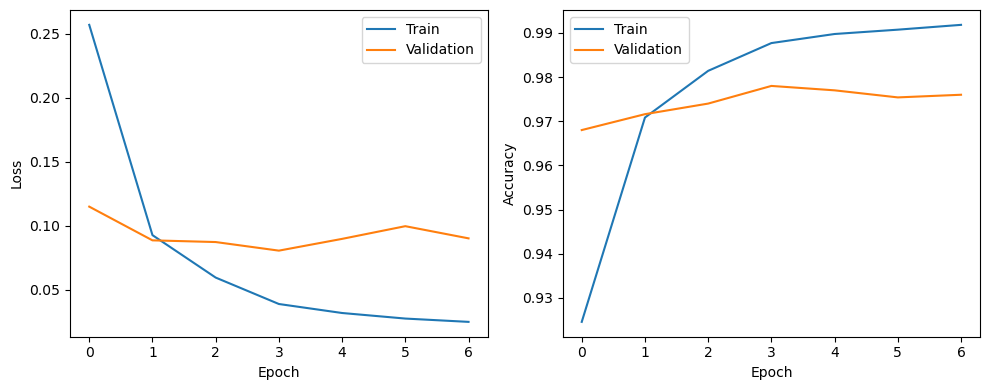

In [4]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

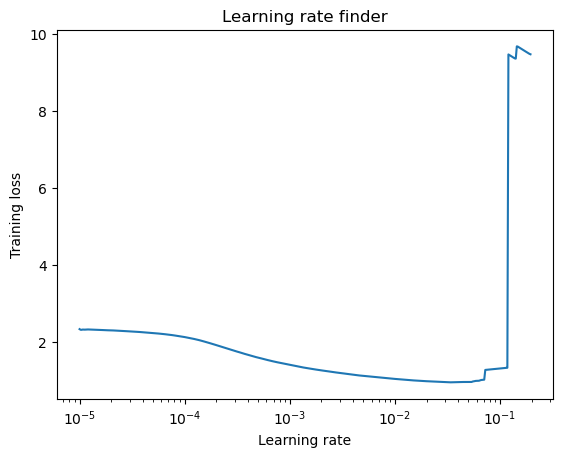

In [7]:
class ExponentialLearningRate(keras.callbacks.Callback):
    def __init__(self, min_lr=1e-5, max_lr=1.0, steps=500):
        super().__init__()
        self.min_lr, self.max_lr, self.steps = min_lr, max_lr, steps
        self.lrs, self.losses = [], []

    def on_train_batch_begin(self, batch, logs=None):
        step = len(self.lrs)
        lr = self.min_lr * (self.max_lr / self.min_lr) ** (step / self.steps)
        self.model.optimizer.learning_rate.assign(lr)

    def on_train_batch_end(self, batch, logs=None):
        self.lrs.append(float(keras.backend.get_value(self.model.optimizer.learning_rate)))
        self.losses.append(logs["loss"])
        if len(self.lrs) >= self.steps:
            self.model.stop_training = True

lr_finder = ExponentialLearningRate()
lr_model = build_mlp(learning_rate=1e-5)
lr_model.fit(X_train, y_train, epochs=1, batch_size=128, callbacks=[lr_finder], verbose=0)

plt.plot(lr_finder.lrs, lr_finder.losses)
plt.xscale("log")
plt.xlabel("Learning rate")
plt.ylabel("Training loss")
plt.title("Learning rate finder")
plt.show()

In [14]:
def model_builder(hp):
    units = hp.Choice("units", [128, 256, 384, 512])
    n_layers = hp.Int("n_layers", 2, 4)
    dropout = hp.Float("dropout", 0.0, 0.4, step=0.2)
    lr = hp.Float("learning_rate", 1e-4, 3e-3, sampling="log")

    model = keras.Sequential([keras.layers.Input(shape=(28, 28)), keras.layers.Flatten()])
    for _ in range(n_layers):
        model.add(keras.layers.Dense(units, activation="relu"))
    model.add(keras.layers.Dropout(dropout))
    model.add(keras.layers.Dense(10, activation="softmax"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

tuner = kt.Hyperband(model_builder, objective="val_accuracy", max_epochs=15, factor=3, directory="mnist_tuning", project_name="deep_mlp")
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    keras.callbacks.TensorBoard(log_dir="logs/mnist_tuning"),
    keras.callbacks.ModelCheckpoint("best_mnist.keras", monitor="val_accuracy", save_best_only=True)]
tuner.search(X_train, y_train, validation_data=(X_val, y_val), epochs=15, batch_size=128, callbacks=callbacks)

best_hp = tuner.get_best_hyperparameters(1)[0]
print("Best hyperparameters:", best_hp.values)
best_model = tuner.get_best_models(1)[0]

Trial 26 Complete [00h 01m 18s]
val_accuracy: 0.9739999771118164

Best val_accuracy So Far: 0.9818000197410583
Total elapsed time: 00h 28m 09s
Best hyperparameters: {'units': 512, 'n_layers': 3, 'dropout': 0.4, 'learning_rate': 0.00031179788402474707, 'tuner/epochs': 15, 'tuner/initial_epoch': 5, 'tuner/bracket': 1, 'tuner/round': 1, 'tuner/trial_id': '0019'}


In [15]:
test_loss, test_acc = best_model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4%}")

Test accuracy: 98.0400%


In [16]:
%load_ext tensorboard
%tensorboard --logdir logs/mnist_tuning